In [2]:
import os
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

In [3]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier

dati = pd.read_pickle("../data/dataset_kb.pkl")

feature_kb = ["esperienza_dev", "esperienza_pub", "autopubblicato"]
y = dati["apprezzato"]
X_completo = dati.drop(columns=["apprezzato"])
X_base = X_completo.drop(columns=feature_kb)

print(X_base.shape, X_completo.shape)

(56662, 22) (56662, 25)


In [4]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
metriche = ["accuracy", "precision", "recall", "f1"]

def valuta(modello, X):
    ris = cross_validate(modello, X, y, cv=cv, scoring=metriche)
    return {m: f"{ris['test_' + m].mean():.3f} ± {ris['test_' + m].std():.3f}" for m in metriche}

In [4]:
riferimento = DummyClassifier(strategy="most_frequent")
print(valuta(riferimento, X_base))

{'accuracy': '0.535 ± 0.000', 'precision': '0.535 ± 0.000', 'recall': '1.000 ± 0.000', 'f1': '0.697 ± 0.000'}


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
print("Base:  ", valuta(logistica, X_base))
print("Con KB:", valuta(logistica, X_completo))

Base:   {'accuracy': '0.626 ± 0.005', 'precision': '0.628 ± 0.005', 'recall': '0.737 ± 0.006', 'f1': '0.678 ± 0.003'}
Con KB: {'accuracy': '0.626 ± 0.004', 'precision': '0.629 ± 0.004', 'recall': '0.736 ± 0.004', 'f1': '0.678 ± 0.002'}


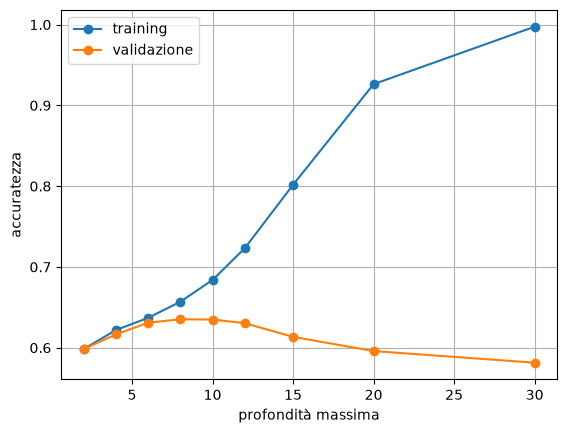

Profondità migliore: 8 - accuratezza 0.635


In [6]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

profondita = [2, 4, 6, 8, 10, 12, 15, 20, 30]
acc_train, acc_valid = [], []

for p in profondita:
    albero = DecisionTreeClassifier(max_depth=p, random_state=42)
    ris = cross_validate(albero, X_completo, y, cv=cv, scoring="accuracy",
                         return_train_score=True)
    acc_train.append(ris["train_score"].mean())
    acc_valid.append(ris["test_score"].mean())

plt.plot(profondita, acc_train, marker="o", label="training")
plt.plot(profondita, acc_valid, marker="o", label="validazione")
plt.xlabel("profondità massima")
plt.ylabel("accuratezza")
plt.legend()
plt.grid(True)
plt.show()

migliore = profondita[acc_valid.index(max(acc_valid))]
print("Profondità migliore:", migliore, "- accuratezza", round(max(acc_valid), 3))

In [7]:
albero = DecisionTreeClassifier(max_depth=migliore, random_state=42)
print("Base:  ", valuta(albero, X_base))
print("Con KB:", valuta(albero, X_completo))

Base:   {'accuracy': '0.630 ± 0.005', 'precision': '0.642 ± 0.007', 'recall': '0.699 ± 0.024', 'f1': '0.669 ± 0.009'}
Con KB: {'accuracy': '0.635 ± 0.004', 'precision': '0.647 ± 0.006', 'recall': '0.702 ± 0.014', 'f1': '0.673 ± 0.006'}


profondità 5 completata
profondità 10 completata
profondità 15 completata
profondità 20 completata
profondità 25 completata


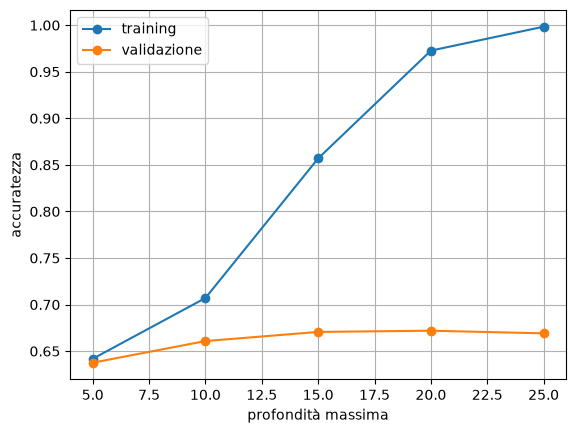

Profondità migliore: 20 - accuratezza 0.672


In [8]:
from sklearn.ensemble import RandomForestClassifier

profondita_rf = [5, 10, 15, 20, 25]
acc_train_rf, acc_valid_rf = [], []

for p in profondita_rf:
    foresta = RandomForestClassifier(n_estimators=100, max_depth=p,
                                     random_state=42, n_jobs=-1)
    ris = cross_validate(foresta, X_completo, y, cv=cv, scoring="accuracy",
                         return_train_score=True)
    acc_train_rf.append(ris["train_score"].mean())
    acc_valid_rf.append(ris["test_score"].mean())
    print("profondità", p, "completata")

plt.plot(profondita_rf, acc_train_rf, marker="o", label="training")
plt.plot(profondita_rf, acc_valid_rf, marker="o", label="validazione")
plt.xlabel("profondità massima")
plt.ylabel("accuratezza")
plt.legend()
plt.grid(True)
plt.show()

migliore_rf = profondita_rf[acc_valid_rf.index(max(acc_valid_rf))]
print("Profondità migliore:", migliore_rf, "- accuratezza", round(max(acc_valid_rf), 3))

In [9]:
foresta = RandomForestClassifier(n_estimators=100, max_depth=migliore_rf,
                                 random_state=42, n_jobs=-1)
print("Base:  ", valuta(foresta, X_base))
print("Con KB:", valuta(foresta, X_completo))

Base:   {'accuracy': '0.665 ± 0.006', 'precision': '0.673 ± 0.007', 'recall': '0.729 ± 0.007', 'f1': '0.700 ± 0.005'}
Con KB: {'accuracy': '0.672 ± 0.006', 'precision': '0.678 ± 0.006', 'recall': '0.737 ± 0.008', 'f1': '0.706 ± 0.006'}


In [5]:
from sklearn.ensemble import RandomForestClassifier

for n in [50, 100, 200, 300]:
    foresta_n = RandomForestClassifier(n_estimators=n, max_depth=20,
                                       random_state=42, n_jobs=-1)
    ris = cross_validate(foresta_n, X_completo, y, cv=cv, scoring="accuracy")
    print(n, "alberi:", round(ris["test_score"].mean(), 3), "±", round(ris["test_score"].std(), 3))

50 alberi: 0.668 ± 0.005
100 alberi: 0.672 ± 0.006
200 alberi: 0.674 ± 0.006
300 alberi: 0.674 ± 0.005


In [6]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv_interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def valuta_annidata(modello, X):
    ris = cross_validate(modello, X, y, cv=cv, scoring=metriche, return_estimator=True)
    risultati = {m: f"{ris['test_' + m].mean():.3f} ± {ris['test_' + m].std():.3f}" for m in metriche}
    profondita_scelte = [stima.best_params_["max_depth"] for stima in ris["estimator"]]
    return risultati, profondita_scelte

In [7]:
albero_annidato = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [2, 4, 6, 8, 10, 12, 15, 20, 30]},
    cv=cv_interna, scoring="accuracy")

for nome, X in [("Base", X_base), ("Con KB", X_completo)]:
    risultati, prof = valuta_annidata(albero_annidato, X)
    print(nome, risultati)
    print("   profondità scelte:", prof)

Base {'accuracy': '0.631 ± 0.006', 'precision': '0.643 ± 0.007', 'recall': '0.697 ± 0.022', 'f1': '0.669 ± 0.009'}
   profondità scelte: [8, 8, 8, 8, 8, 8, 10, 10, 8, 8]
Con KB {'accuracy': '0.635 ± 0.004', 'precision': '0.646 ± 0.005', 'recall': '0.703 ± 0.013', 'f1': '0.673 ± 0.005'}
   profondità scelte: [8, 8, 8, 8, 8, 8, 10, 8, 8, 8]


In [8]:
foresta_annidata = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    param_grid={"max_depth": [5, 10, 15, 20, 25]},
    cv=cv_interna, scoring="accuracy")

for nome, X in [("Base", X_base), ("Con KB", X_completo)]:
    risultati, prof = valuta_annidata(foresta_annidata, X)
    print(nome, risultati)
    print("   profondità scelte:", prof)

Base {'accuracy': '0.666 ± 0.005', 'precision': '0.672 ± 0.005', 'recall': '0.736 ± 0.008', 'f1': '0.702 ± 0.005'}
   profondità scelte: [15, 15, 15, 20, 20, 15, 15, 15, 20, 15]
Con KB {'accuracy': '0.672 ± 0.006', 'precision': '0.678 ± 0.006', 'recall': '0.737 ± 0.007', 'f1': '0.706 ± 0.005'}
   profondità scelte: [20, 20, 20, 20, 20, 20, 15, 15, 20, 20]
